# Run the base model

Run the cells from top to bottom. README.md explains the model and the code.

In [1]:
# Mesa provides the agent-based modelling tools.
import mesa

# pandas stores the results in tables.
import pandas as pd

# matplotlib shows the figures.
import matplotlib.pyplot as plt

# These lines load the model and two figure functions from the model folder.
from model.model import WaterAccessModel
from model.plots import plot_results, plot_comparison

# Mesa: The model was written for Mesa 3.5.0.
print(f"Installed Mesa: {mesa.__version__}")

Installed Mesa: 3.5.0


## 1. Choose the settings

Change the values below and run the cells again. Start with the smallest map.

In [2]:
# The map: "turin_2x2", "turin_4x4", "turin_6x6" or "turin_full".
network_name = "turin_2x2"

# Each step lasts 1, 6 or 24 hours.
time_step_hours = 6

# The run lasts this many days.
simulation_days = 20

# Each group holds about this many residents.
people_per_group = 10

# Each profile has a fraction of the residents and a walking distance in metres.
profiles = {
    "elderly": {"fraction": 0.25, "walking_distance_m": 300},
    "other": {"fraction": 0.75, "walking_distance_m": 1000},
}

# With True, groups share water points with their contacts once a day.
share_information = True

# The same seed and settings give the same run.
random_seed = 42

## 2. Create and run the model

The cell creates the model, runs it for the chosen number of days and shows the first rows of the results. Each row is one step.

In [3]:
water_model = WaterAccessModel(
    network_name=network_name,
    time_step_hours=time_step_hours,
    simulation_days=simulation_days,
    people_per_group=people_per_group,
    profiles=profiles,
    share_information=share_information,
    rng=random_seed,  # Mesa: rng sets the seed of the random numbers.
)

# Mesa: run_for() calls step() once for every step of the run.
water_model.run_for(water_model.number_of_steps)

# Mesa: The DataCollector returns the results as a table with one row per step.
model_data = water_model.datacollector.get_model_vars_dataframe()
model_data.head().round(2)

,Time (days),Water need met (%),Groups without a point (%),Broken pipes,"Water need met, elderly (%)","Water need met, other (%)"
0,0.00,0.00,13.90,616,0.00,0.00
1,0.25,37.84,71.58,611,34.30,39.02
2,0.50,38.00,71.66,606,34.47,39.17
3,0.75,38.31,72.69,601,35.51,39.24
4,1.00,37.40,65.70,596,35.03,38.19


## 3. Look at the results

The left panel shows how much of the water need was met, for all residents and for each profile. The middle panel shows the share of groups that know no water point. The right panel shows how many pipes are still broken.

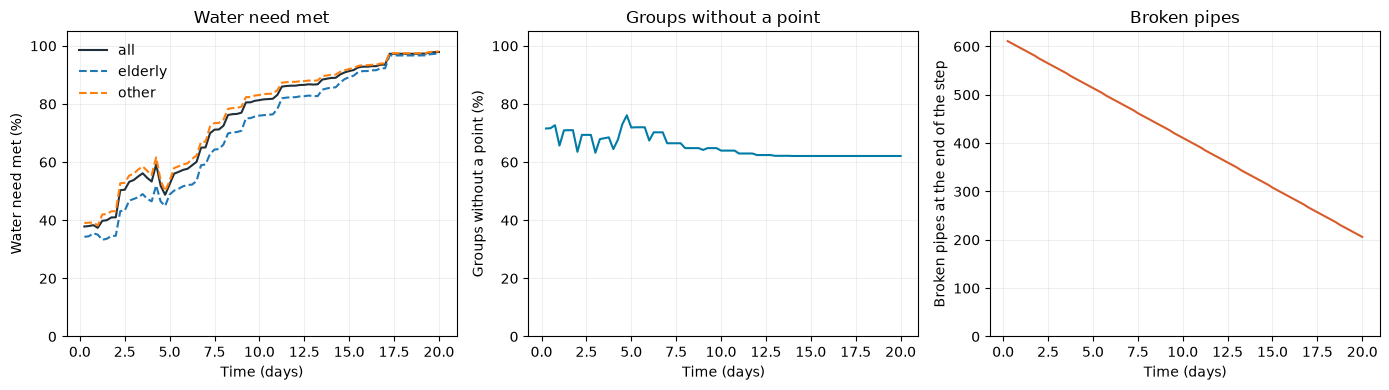

In [4]:
plot_results(water_model)
plt.show()

## 4. Compare two runs

The second run is the same as the first, except that groups do not share information. Use the same function to compare your own changes.

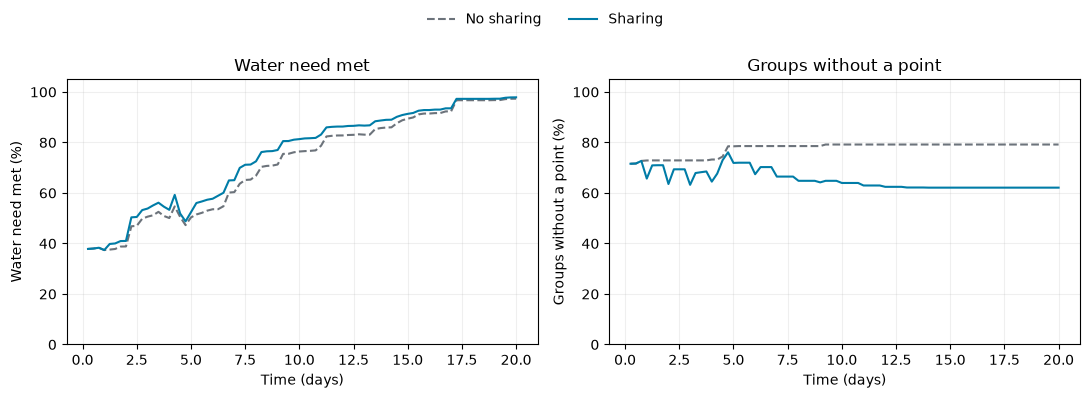

In [5]:
model_without_sharing = WaterAccessModel(
    network_name=network_name,
    time_step_hours=time_step_hours,
    simulation_days=simulation_days,
    people_per_group=people_per_group,
    profiles=profiles,
    share_information=False,  # This is the only change.
    rng=random_seed,
)
model_without_sharing.run_for(model_without_sharing.number_of_steps)

plot_comparison(model_without_sharing, water_model, label_a="No sharing", label_b="Sharing")
plt.show()

## 5. Repeat with other seeds

One run can be a matter of chance. The cell repeats both settings with five seeds and shows the average water need met for each run. Use more seeds before you draw a conclusion.

In [6]:
# Mesa: batch_run runs the model for every combination of settings and seeds.
results = mesa.batch_run(
    WaterAccessModel,
    parameters={
        "network_name": network_name,
        "time_step_hours": time_step_hours,
        "simulation_days": simulation_days,
        "people_per_group": people_per_group,
        "profiles": [profiles],  # A dictionary must be inside a list.
        "share_information": [False, True],  # A list gives one run per value.
    },
    rng=[100, 101, 102, 103, 104],
    max_steps=simulation_days * 24,  # This limit is high enough for hourly steps.
    number_processes=1,
    data_collection_period=1,
    display_progress=False,
)

# The first row of each run is the start, before any water is used, so it is left out.
experiment_data = pd.DataFrame(results)
experiment_data = experiment_data[experiment_data["Time (days)"] > 0]

# The table shows one row per seed and one column per setting.
experiment_data.pivot_table(
    index="rng", columns="share_information", values="Water need met (%)", aggfunc="mean"
).round(1)

share_information,False,True
rng,,
100,78.4,81.9
101,82.2,86.4
102,69.1,74.0
103,68.6,71.3
104,79.1,81.2
